# 01 · Data Transformation
**Module 2 (CO2)** — Bike Sharing Demand EDA

| Syllabus topic | Section |
|---|---|
| Transformation techniques: data deduplication, replacing values | §2, §3 |
| Discretization and binning | §4 |
| Missing data & traditional handling methods | §5 |
| Maximum Likelihood Estimation | §6 |

**Dataset:** [UCI Bike Sharing Dataset](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset) — hourly rentals from Capital Bikeshare, Washington D.C., 2011–2012 (17,379 rows), joined with weather data.

| Column | Meaning |
|---|---|
| `dteday`, `hr` | date and hour (0–23) |
| `season` | 1 = spring, 2 = summer, 3 = fall, 4 = winter |
| `yr` | 0 = 2011, 1 = 2012 |
| `holiday`, `workingday` | 0/1 flags |
| `weathersit` | 1 = clear … 4 = heavy rain/snow |
| `temp`, `atemp`, `hum`, `windspeed` | **normalised** (divided by 41, 50, 100, 67) |
| `casual`, `registered`, `cnt` | rentals by casual users, registered users, total |

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize

from utils import set_style, save_fig, load_raw_hourly, PROCESSED, PALETTE

set_style()
pd.set_option("display.max_columns", 30)
np.random.seed(42)

## 1. Load and inspect the raw data

In [2]:
raw = load_raw_hourly()
print("Shape:", raw.shape)
raw.head()

Shape: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[us]
 2   season      17379 non-null  int64         
 3   yr          17379 non-null  int64         
 4   mnth        17379 non-null  int64         
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  int64         
 7   weekday     17379 non-null  int64         
 8   workingday  17379 non-null  int64         
 9   weathersit  17379 non-null  int64         
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64         
 16  cnt         17379 non-null  int64

The UCI file is already quite clean. To practise the Module 2 techniques on realistic problems we **simulate common real-world data-quality issues** with a fixed random seed (so results are reproducible). Because we know the true values, we can measure how well each cleaning method recovers them.

| Issue | How it is introduced | Real or simulated? |
|---|---|---|
| Duplicate rows | 150 random rows appended again (e.g. a logging retry) | simulated |
| Missing `temp` and `hum` | 5% of values blanked (sensor dropouts) | simulated |
| `windspeed = 0` | already in the data — a calm-wind reading of exactly 0 is a sensor gap | **real** |
| Missing hours | some hours never appear in the file | **real** |

In [4]:
df = raw.copy()

# (a) duplicates
dup_rows = df.sample(150, random_state=1)
df = pd.concat([df, dup_rows]).sample(frac=1, random_state=2).reset_index(drop=True)

# (b) missing values — keep the ground truth for evaluation later
truth = raw.set_index("instant")[["temp", "hum"]].copy()
for col in ["temp", "hum"]:
    mask = np.random.rand(len(df)) < 0.05
    df.loc[mask, col] = np.nan

print("Rows after injecting duplicates:", len(df))
print("Missing values:\n", df.isna().sum()[lambda s: s > 0])

Rows after injecting duplicates: 17529
Missing values:
 temp    885
hum     828
dtype: int64


## 2. Data deduplication
Duplicates inflate counts and bias every statistic. There are two kinds:
1. **Exact duplicates** — every column is identical.
2. **Key duplicates** — the same logical record (`dteday` + `hr`) appears more than once, even if some fields differ.

Note: a row whose value was blanked in one copy but not the other is a key duplicate but *not* an exact duplicate, so we check both.

In [5]:
print("Exact duplicate rows   :", df.duplicated().sum())
print("Key duplicates (date+hr):", df.duplicated(subset=["dteday", "hr"]).sum())

Exact duplicate rows   : 125
Key duplicates (date+hr): 150


In [6]:
# Look at one duplicated record
key = df[df.duplicated(subset=["dteday", "hr"], keep=False)].sort_values(["dteday", "hr"])
key.head(6)

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
8231,23,2011-01-01,1,0,1,22,0,6,0,2,0.40,0.4091,0.94,0.2239,11,17,28
9849,23,2011-01-01,1,0,1,22,0,6,0,2,0.40,0.4091,0.94,0.2239,11,17,28
8385,45,2011-01-02,1,0,1,21,0,0,0,1,0.26,0.2273,0.44,0.3284,11,20,31
13668,45,2011-01-02,1,0,1,21,0,0,0,1,0.26,0.2273,0.44,0.3284,11,20,31
1362,221,2011-01-10,1,0,1,11,0,1,1,2,0.16,0.1364,0.47,0.2836,2,28,30
5844,221,2011-01-10,1,0,1,11,0,1,1,2,0.16,0.1364,0.47,0.2836,2,28,30


In [7]:
# Sort so that, within each key, the row with the fewest missing values comes first,
# then keep the first occurrence.
df["_n_missing"] = df.isna().sum(axis=1)
df = (df.sort_values(["dteday", "hr", "_n_missing"])
        .drop_duplicates(subset=["dteday", "hr"], keep="first")
        .drop(columns="_n_missing")
        .sort_values("instant")
        .reset_index(drop=True))

print("Rows after deduplication:", len(df), "| original:", len(raw))
assert len(df) == len(raw)

Rows after deduplication: 17379 | original: 17379


## 3. Replacing values
Three types of replacement are needed here:
1. **Codes → readable labels** (`season`, `weathersit`, `weekday`, `yr`) using `map` / `replace`.
2. **Undo normalisation** so values are in real units (°C, %, km/h).
3. **Invalid sentinel values → NaN** (`windspeed == 0`), plus merging a very rare category.

In [8]:
df["season"] = df["season"].replace({1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"})
df["year"] = df["yr"].map({0: 2011, 1: 2012})
df["weekday"] = df["weekday"].map(dict(enumerate(["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"])))

print(df["weathersit"].value_counts().sort_index())

weathersit
1    11413
2     4544
3     1419
4        3
Name: count, dtype: int64


Category 4 (*heavy rain/snow*) has only **3 rows** — too few to analyse on its own, so we merge it into category 3.

In [9]:
df["weather"] = df["weathersit"].replace({4: 3}).map({1: "Clear", 2: "Mist/Cloudy", 3: "Rain/Snow"})
df["weather"].value_counts()

weather
Clear          11413
Mist/Cloudy     4544
Rain/Snow       1422
Name: count, dtype: int64

In [10]:
# Undo normalisation (factors from the dataset's Readme)
df["temp"] = df["temp"] * 41          # °C
df["atemp"] = df["atemp"] * 50        # feels-like °C
df["hum"] = df["hum"] * 100           # %
df["windspeed"] = df["windspeed"] * 67  # km/h

# Hourly wind readings of exactly 0 are sensor gaps, not real calm air
print("windspeed == 0 rows:", (df["windspeed"] == 0).sum())
df["windspeed"] = df["windspeed"].replace(0, np.nan)

df = df.rename(columns={"hum": "humidity", "hr": "hour", "mnth": "month"})
df[["season", "year", "weekday", "weather", "temp", "atemp", "humidity", "windspeed"]].head()

windspeed == 0 rows: 2180


,season,year,weekday,weather,temp,atemp,humidity,windspeed
0,Spring,2011,Sat,Clear,9.84,14.395,81.0,NaN
1,Spring,2011,Sat,Clear,9.02,13.635,80.0,NaN
2,Spring,2011,Sat,Clear,9.02,13.635,80.0,NaN
3,Spring,2011,Sat,Clear,9.84,14.395,75.0,NaN
4,Spring,2011,Sat,Clear,9.84,14.395,75.0,NaN


## 4. Discretization and binning
Binning turns a continuous variable into categories — useful for group comparisons, reducing noise and creating readable features.

| Method | pandas | Bins have… |
|---|---|---|
| Equal-width | `pd.cut(x, bins=k)` | equal value ranges, unequal counts |
| Equal-frequency (quantile) | `pd.qcut(x, q=k)` | equal counts, unequal ranges |
| Custom / domain | `pd.cut(x, bins=[...], labels=[...])` | boundaries chosen by meaning |

In [11]:
# (a) Equal-width: temperature into 4 bands
df["temp_band"] = pd.cut(df["temp"], bins=4, labels=["Cold", "Mild", "Warm", "Hot"])
print("Equal-width bin edges:", pd.cut(df["temp"], bins=4).cat.categories.tolist())
print(df["temp_band"].value_counts().sort_index())

Equal-width bin edges: [Interval(0.78, 10.865, closed='right'), Interval(10.865, 20.91, closed='right'), Interval(20.91, 30.955, closed='right'), Interval(30.955, 41.0, closed='right')]
temp_band
Cold    2441
Mild    5942
Warm    6587
Hot     1536
Name: count, dtype: int64


In [12]:
# (b) Equal-frequency: rental count into quartiles -> demand level
df["demand_level"] = pd.qcut(df["cnt"], q=4, labels=["Low", "Medium", "High", "Very High"])
print("Quantile edges:", pd.qcut(df["cnt"], q=4).cat.categories.tolist())
print(df["demand_level"].value_counts().sort_index())

Quantile edges: [Interval(0.999, 40.0, closed='right'), Interval(40.0, 142.0, closed='right'), Interval(142.0, 281.0, closed='right'), Interval(281.0, 977.0, closed='right')]
demand_level
Low          4377
Medium       4331
High         4345
Very High    4326
Name: count, dtype: int64


In [13]:
# (c) Custom domain bins: hour of day
df["time_of_day"] = pd.cut(df["hour"], bins=[0, 6, 10, 16, 20, 24], right=False,
                           labels=["Night", "Morning Peak", "Midday", "Evening Peak", "Late Evening"])
df.groupby("time_of_day", observed=True)["cnt"].agg(["count", "mean"]).round(1)

,count,mean
time_of_day,,
Night,4276,24.9
Morning Peak,2906,216.7
Midday,4369,230.2
Evening Peak,2916,377.6
Late Evening,2912,154.4


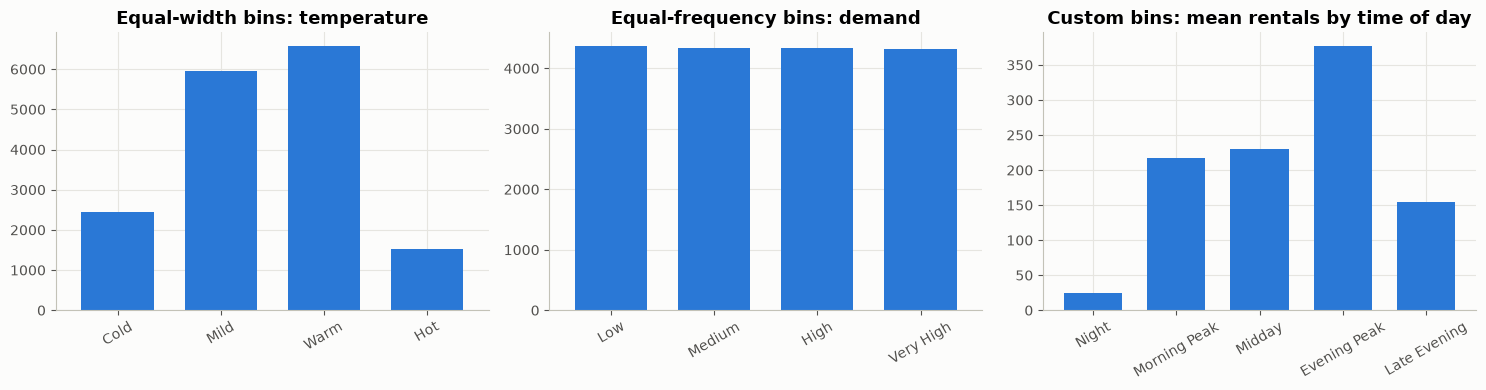

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df["temp_band"].value_counts().sort_index().plot.bar(ax=axes[0], color=PALETTE[0], width=0.7)
axes[0].set_title("Equal-width bins: temperature")
df["demand_level"].value_counts().sort_index().plot.bar(ax=axes[1], color=PALETTE[0], width=0.7)
axes[1].set_title("Equal-frequency bins: demand")
df.groupby("time_of_day", observed=True)["cnt"].mean().plot.bar(ax=axes[2], color=PALETTE[0], width=0.7)
axes[2].set_title("Custom bins: mean rentals by time of day")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
    ax.set_xlabel("")
fig.tight_layout()
save_fig(fig, "01_binning")
plt.show()

**Observation:** equal-width bins are uneven in size (few "Hot" hours), while quantile bins hold about the same number of rows each. The custom hour bins already show the commuter pattern — morning and evening peaks are far busier than night.

## 5. Missing data
### 5.1 Types of missingness
- **MCAR** (Missing Completely At Random) — missingness is unrelated to any data (our simulated sensor dropouts).
- **MAR** (Missing At Random) — depends on *observed* variables (e.g. wind sensor fails more often in winter).
- **MNAR** (Missing Not At Random) — depends on the missing value itself (e.g. a sensor that can't record very low wind, so those readings come out as 0).

### 5.2 How much is missing?

In [15]:
missing = pd.DataFrame({"n_missing": df.isna().sum(), "pct": (df.isna().mean() * 100).round(2)})
missing = missing[missing.n_missing > 0]
missing

,n_missing,pct
temp,873,5.02
humidity,815,4.69
windspeed,2180,12.54
temp_band,873,5.02


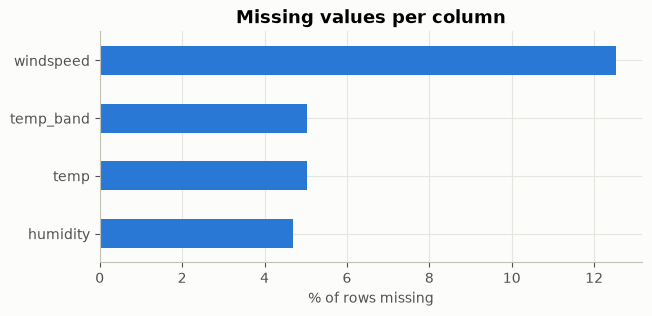

In [16]:
fig, ax = plt.subplots(figsize=(7, 3))
missing["pct"].sort_values().plot.barh(ax=ax, color=PALETTE[0])
ax.set_xlabel("% of rows missing")
ax.set_title("Missing values per column")
save_fig(fig, "01_missing_pct")
plt.show()

In [17]:
# Is windspeed missingness related to other variables? (MCAR vs MAR check)
df.assign(wind_missing=df["windspeed"].isna()).groupby("season")["wind_missing"].mean().round(3)

season
Fall      0.141
Spring    0.103
Summer    0.090
Winter    0.168
Name: wind_missing, dtype: float64

Windspeed missingness varies by season, so it is closer to **MAR/MNAR** than MCAR — a simple global mean is not ideal; time-aware interpolation is safer.

### 5.3 Traditional methods, compared against the ground truth
Because we blanked `temp` ourselves, we can measure the error of each method on exactly those cells.

In [18]:
ts = df.set_index(pd.to_datetime(df["dteday"]) + pd.to_timedelta(df["hour"], unit="h"))
true_temp = truth["temp"].reindex(df["instant"]).values * 41
miss = ts["temp"].isna().values

methods = {
    "Mean imputation": ts["temp"].fillna(ts["temp"].mean()),
    "Median imputation": ts["temp"].fillna(ts["temp"].median()),
    "Group mean (month × hour)": ts["temp"].fillna(ts.groupby(["month", "hour"])["temp"].transform("mean")),
    "Forward fill": ts["temp"].ffill(),
    "Backward fill": ts["temp"].bfill(),
    "Linear interpolation": ts["temp"].interpolate(method="linear"),
    "Time interpolation": ts["temp"].interpolate(method="time"),
}
results = pd.DataFrame({
    name: {"RMSE (°C)": np.sqrt(np.mean((filled.values[miss] - true_temp[miss]) ** 2)),
           "MAE (°C)": np.mean(np.abs(filled.values[miss] - true_temp[miss]))}
    for name, filled in methods.items()
}).T.sort_values("RMSE (°C)").round(3)

print("Listwise deletion would drop", df[["temp", "humidity"]].isna().any(axis=1).sum(),
      "rows (", round(df[["temp", "humidity"]].isna().any(axis=1).mean() * 100, 1), "% of data )")
results

Listwise deletion would drop 1651 rows ( 9.5 % of data )


,RMSE (°C),MAE (°C)
Linear interpolation,0.575,0.397
Time interpolation,0.575,0.398
Backward fill,0.985,0.668
Forward fill,1.021,0.665
Group mean (month × hour),3.533,2.798
Mean imputation,7.691,6.586
Median imputation,7.698,6.589


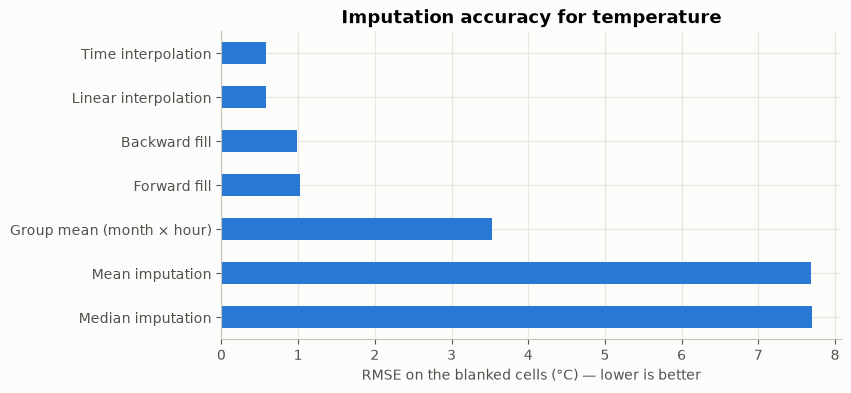

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
results["RMSE (°C)"].sort_values(ascending=False).plot.barh(ax=ax, color=PALETTE[0])
ax.set_xlabel("RMSE on the blanked cells (°C) — lower is better")
ax.set_title("Imputation accuracy for temperature")
save_fig(fig, "01_imputation_comparison")
plt.show()

**Findings**
- **Listwise deletion** throws away ~10% of rows — wasteful for a time series.
- **Mean/median imputation** ignore time and season, giving errors of ~8 °C.
- **Interpolation / fill** use neighbouring hours and are far more accurate (< 1 °C), because temperature changes smoothly hour to hour.

We therefore use **time interpolation** for the numeric weather columns.

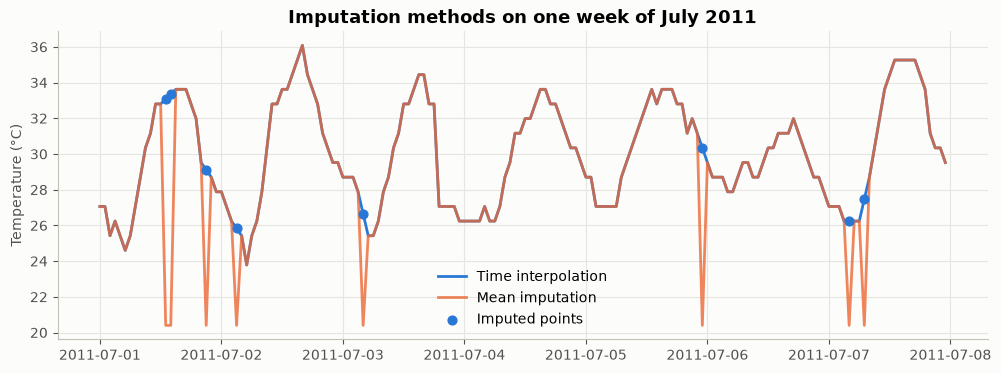

In [20]:
# Show the effect on a short window
week = ts.loc["2011-07-01":"2011-07-07"].index
gaps = ts.loc[week, "temp"].isna()
interp, mean_fill = methods["Time interpolation"][week], methods["Mean imputation"][week]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(interp, color=PALETTE[0], label="Time interpolation")
ax.plot(mean_fill, color=PALETTE[1], alpha=0.8, label="Mean imputation")
ax.scatter(week[gaps], interp[gaps], color=PALETTE[0], s=40, zorder=3, label="Imputed points")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Imputation methods on one week of July 2011")
ax.legend()
save_fig(fig, "01_imputation_week")
plt.show()

### 5.4 Missing time stamps
2 years × 365/366 days × 24 hours = 17,544 hours, but the file has 17,379 rows. Some hours are missing entirely (the system was down or nobody rented a bike).

In [21]:
full_range = pd.date_range(ts.index.min(), ts.index.max(), freq="h")
missing_hours = full_range.difference(ts.index)
print("Expected hours:", len(full_range), "| present:", len(ts), "| missing:", len(missing_hours))
pd.Series(missing_hours.date).value_counts().head(8)

Expected hours: 17544 | present: 17379 | missing: 165


2012-10-29    23
2011-01-27    16
2012-10-30    13
2011-01-18    12
2011-01-26     8
2011-08-28     7
2011-02-22     6
2011-08-27     6
Name: count, dtype: int64

Most gaps are isolated early-morning hours with near-zero demand, but **2012-10-29/30** (Hurricane Sandy) and several days in **January 2011** (winter storms) lose many hours. We leave these hours absent (rather than inventing rentals); resampling in later notebooks handles them naturally.

## 6. Maximum Likelihood Estimation (MLE)
MLE chooses the parameters $\theta$ that make the observed data most probable:
$$\hat\theta = \arg\max_\theta \; \log L(\theta) = \arg\max_\theta \sum_{i=1}^n \log f(x_i \mid \theta)$$

### 6.1 Normal distribution for temperature
For $x_i \sim \mathcal N(\mu, \sigma^2)$ the closed-form MLEs are
$\hat\mu = \bar x$ and $\hat\sigma^2 = \frac1n\sum (x_i-\bar x)^2$ (note: divide by *n*, not *n − 1*).

In [22]:
temp = methods["Time interpolation"].values

# Analytical MLE
mu_hat = temp.mean()
sigma_hat = np.sqrt(np.mean((temp - mu_hat) ** 2))

# Numerical MLE: minimise the negative log-likelihood
def neg_log_lik(params, x):
    mu, log_sigma = params
    return -np.sum(stats.norm.logpdf(x, loc=mu, scale=np.exp(log_sigma)))

opt = optimize.minimize(neg_log_lik, x0=[10, np.log(5)], args=(temp,))
mu_num, sigma_num = opt.x[0], np.exp(opt.x[1])

# scipy's built-in fit also uses MLE
mu_sp, sigma_sp = stats.norm.fit(temp)

pd.DataFrame({"mu": [mu_hat, mu_num, mu_sp], "sigma": [sigma_hat, sigma_num, sigma_sp]},
             index=["Closed form", "Numerical optimisation", "scipy.stats.norm.fit"]).round(4)

,mu,sigma
Closed form,20.3765,7.8942
Numerical optimisation,20.3765,7.8942
scipy.stats.norm.fit,20.3765,7.8942


All three agree. Now check the fit visually:

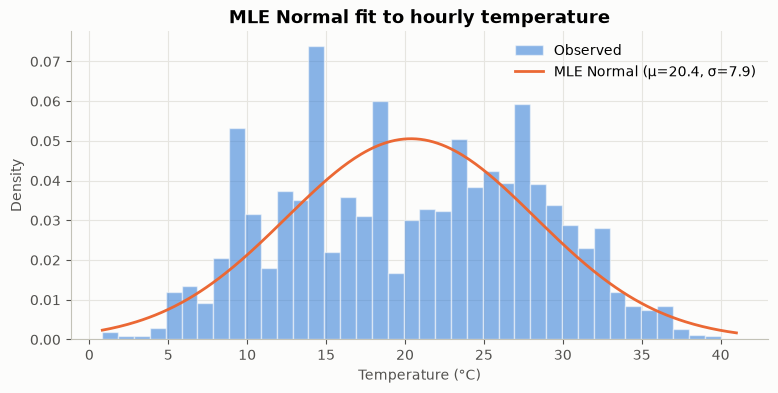

In [23]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(temp, bins=40, density=True, color=PALETTE[0], alpha=0.55, edgecolor="#fcfcfb", label="Observed")
xs = np.linspace(temp.min(), temp.max(), 300)
ax.plot(xs, stats.norm.pdf(xs, mu_hat, sigma_hat), color=PALETTE[1],
        label=f"MLE Normal (μ={mu_hat:.1f}, σ={sigma_hat:.1f})")
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Density")
ax.set_title("MLE Normal fit to hourly temperature")
ax.legend()
save_fig(fig, "01_mle_normal")
plt.show()

### 6.2 Poisson distribution for night-time rentals
Counts are naturally modelled by a Poisson distribution, $P(k)=\frac{\lambda^k e^{-\lambda}}{k!}$, whose MLE is $\hat\lambda=\bar k$. We use rentals at **4 AM**, a low-count hour where the Poisson model is plausible.

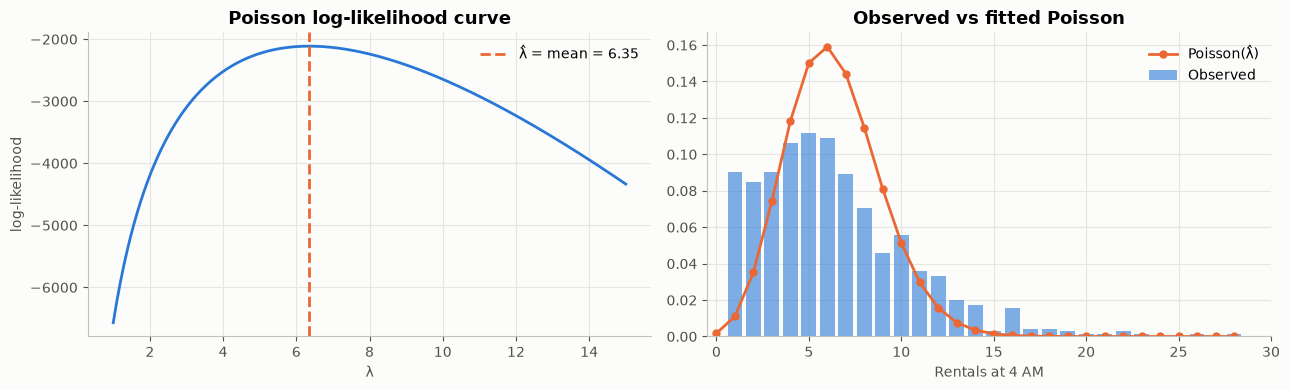

mean = 6.35, variance = 17.15


In [24]:
k = df.loc[df["hour"] == 4, "cnt"].values
lambdas = np.linspace(1, 15, 300)
loglik = [stats.poisson.logpmf(k, lam).sum() for lam in lambdas]
lam_hat = k.mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(lambdas, loglik, color=PALETTE[0])
axes[0].axvline(lam_hat, color=PALETTE[1], linestyle="--", label=f"λ̂ = mean = {lam_hat:.2f}")
axes[0].set_xlabel("λ")
axes[0].set_ylabel("log-likelihood")
axes[0].set_title("Poisson log-likelihood curve")
axes[0].legend()

vals = np.arange(0, k.max() + 1)
obs = pd.Series(k).value_counts(normalize=True).reindex(vals, fill_value=0)
axes[1].bar(vals, obs.values, color=PALETTE[0], alpha=0.6, label="Observed")
axes[1].plot(vals, stats.poisson.pmf(vals, lam_hat), "o-", color=PALETTE[1], markersize=5, label="Poisson(λ̂)")
axes[1].set_xlim(-0.5, 30)
axes[1].set_xlabel("Rentals at 4 AM")
axes[1].set_title("Observed vs fitted Poisson")
axes[1].legend()
fig.tight_layout()
save_fig(fig, "01_mle_poisson")
plt.show()
print(f"mean = {k.mean():.2f}, variance = {k.var():.2f}")

**Observation:** the log-likelihood peaks exactly at the sample mean. However the variance is larger than the mean (*over-dispersion*), so the Poisson fit is too narrow — a Negative Binomial would fit better. MLE gives the *best* parameters for a chosen model; it does not tell us the model itself is right.

**Link to missing data:** MLE is also the basis of modern missing-data methods. Under MAR, maximising the likelihood of only the observed values (e.g. via the EM algorithm, covered in notebook 04) gives unbiased estimates, unlike mean imputation.

## 7. Save the clean datasets
Apply the chosen cleaning steps and save hourly and daily files for the next notebooks.

In [25]:
ts = ts.copy()
for col in ["temp", "humidity", "windspeed"]:
    ts[col] = ts[col].interpolate(method="time", limit_direction="both")
ts["temp_band"] = pd.cut(ts["temp"], bins=4, labels=["Cold", "Mild", "Warm", "Hot"])

hourly = ts.reset_index(names="datetime")[[
    "datetime", "dteday", "year", "month", "hour", "season", "holiday", "weekday", "workingday",
    "weather", "temp", "atemp", "humidity", "windspeed", "casual", "registered", "cnt",
    "temp_band", "demand_level", "time_of_day"]].rename(columns={"dteday": "date"})
hourly[["temp", "atemp", "humidity", "windspeed"]] = hourly[["temp", "atemp", "humidity", "windspeed"]].round(2)
print("Remaining missing values:", hourly.isna().sum().sum())

daily = hourly.groupby("date").agg(
    year=("year", "first"), month=("month", "first"), season=("season", "first"),
    holiday=("holiday", "first"), weekday=("weekday", "first"), workingday=("workingday", "first"),
    weather=("weather", lambda s: s.mode()[0]),
    temp=("temp", "mean"), atemp=("atemp", "mean"), humidity=("humidity", "mean"),
    windspeed=("windspeed", "mean"),
    casual=("casual", "sum"), registered=("registered", "sum"), cnt=("cnt", "sum"),
).round(2).reset_index()

PROCESSED.mkdir(parents=True, exist_ok=True)
hourly.to_csv(PROCESSED / "hour_clean.csv", index=False)
daily.to_csv(PROCESSED / "day_clean.csv", index=False)
print("hourly:", hourly.shape, "| daily:", daily.shape)
hourly.head()

Remaining missing values: 0
hourly: (17379, 20) | daily: (731, 15)


,datetime,date,year,month,hour,season,holiday,weekday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,cnt,temp_band,demand_level,time_of_day
0,2011-01-01 00:00:00,2011-01-01,2011,1,0,Spring,0,Sat,0,Clear,9.84,14.40,81.0,6.0,3,13,16,Cold,Low,Night
1,2011-01-01 01:00:00,2011-01-01,2011,1,1,Spring,0,Sat,0,Clear,9.02,13.64,80.0,6.0,8,32,40,Cold,Low,Night
2,2011-01-01 02:00:00,2011-01-01,2011,1,2,Spring,0,Sat,0,Clear,9.02,13.64,80.0,6.0,5,27,32,Cold,Low,Night
3,2011-01-01 03:00:00,2011-01-01,2011,1,3,Spring,0,Sat,0,Clear,9.84,14.40,75.0,6.0,3,10,13,Cold,Low,Night
4,2011-01-01 04:00:00,2011-01-01,2011,1,4,Spring,0,Sat,0,Clear,9.84,14.40,75.0,6.0,0,1,1,Cold,Low,Night


## Summary
- Removed **150 duplicate** records using a date + hour key (keeping the most complete copy).
- Replaced numeric codes with labels, converted values back to real units, merged a 3-row weather category and turned **2,180 invalid wind readings** into proper missing values.
- Created binned features: `temp_band` (equal-width), `demand_level` (equal-frequency) and `time_of_day` (custom).
- Compared 7 traditional imputation methods; **time interpolation** was most accurate (RMSE < 1 °C vs ~8 °C for mean imputation).
- Used **MLE** to fit Normal and Poisson models, and showed that over-dispersion makes the Poisson model too narrow for rental counts.